# M02 概覽 | 把 prepare 與 convert 拆開：observer 從哪來、變成什麼

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m02_observer_fakequant/00_overview.ipynb)

M01 把 `prepare_pt2e` 和 `convert_pt2e` 當成黑盒子用：一個插 observer，一個把 observer 換成 q/dq。
這一章把兩個盒子打開，並且不靠它們、自己動手做一次，證明裡面只有幾個改圖動作。
後面三本 notebook（M02-1～M02-3）逐一動手驗證。

這一章只管 observer 本身與改圖的機制；observer 插在**哪裡**由 Quantizer 決定，是下一章 M03 的主題。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m02_observer_fakequant")

In [1]:
#| echo: false
import copy

import torch

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    MovingAverageMinMaxObserver,
    convert_pt2e,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.viz import draw_stages

quiet()
_ = torch.manual_seed(0)
QD = torch.ops.quantized_decomposed

## 為什麼要拆開

寫自己的 quantizer（M03）、看懂 BN 怎麼折（M04）、排 QAT 的訓練流程（M06），都要知道 prepare 和 convert 在圖上做了什麼。
否則出問題時只能猜：observer 到底在算什麼？它怎麼出現在圖上？convert 之後的 scale 從哪來？

這一章回答三個問題：

| 問題 | 一句話的答案 | 動手驗證 |
|---|---|---|
| observer 在算什麼？ | 記錄數值範圍，算出 scale 與 zero point；不同 observer 選範圍的方式不同 | M02-1 |
| observer 怎麼插進圖？ | 掛一個子模組，插一個 `call_module` node，改接下游 | M02-2 |
| observer 怎麼變成 q/dq？ | 取出 qparams，換成 quantize、dequantize 兩個 node，再預先算好 int8 weight | M02-3 |

## 先看一個例子：全部手做的 conv → relu

和 M01 同一個 conv → relu，三個階段的圖長得也一樣。差別是：**這裡第二、三階段都沒有呼叫 `prepare_pt2e`、`convert_pt2e`**，
而是用 M02-2、M02-3 的改圖程式手做的（這裡把程式藏起來，只看結果）。第一個 row 是 export 與手插 observer，第二個 row 是手換 q/dq：

- **手插 observer**：在輸入 `x`、conv 的 weight、relu 的輸出各插一個 observer（綠框），種類照 XNNPACKQuantizer 的設定。
- **手換 q/dq**：校準之後，每個 observer 換成一對 quantize → dequantize，scale 與 zero point 寫在 node 上。

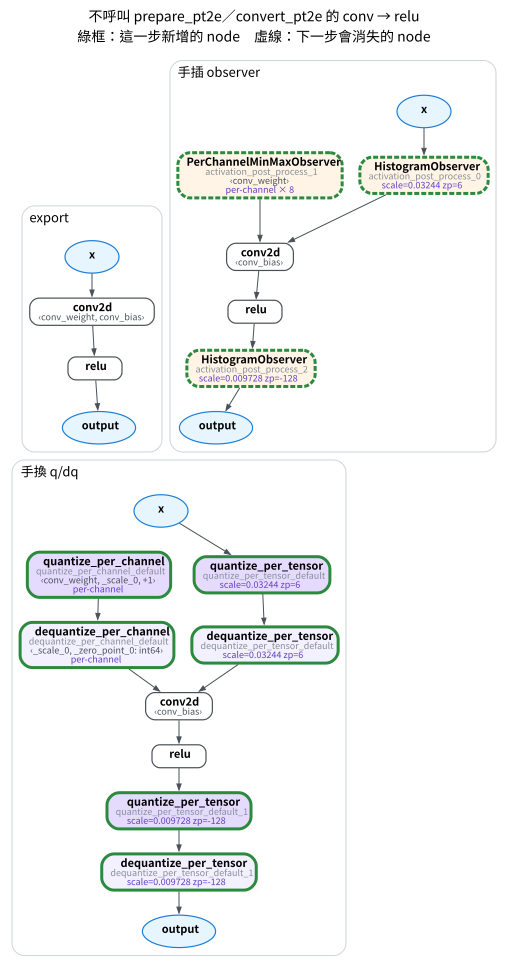

In [2]:
#| echo: false
def insert_after(gm, node, module, name):
    gm.add_submodule(name, module)
    with gm.graph.inserting_after(node):
        new = gm.graph.call_module(name, (node,))
    node.replace_all_uses_with(new, delete_user_cb=lambda user: user is not new)


def make(spec):
    kw = dict(dtype=spec.dtype, qscheme=spec.qscheme, quant_min=spec.quant_min, quant_max=spec.quant_max)
    if spec.ch_axis is not None:
        kw["ch_axis"] = spec.ch_axis
    return spec.observer_or_fake_quant_ctr.with_args(**kw)()


def to_qdq(gm):
    g = gm.graph
    for k, (node, obs) in enumerate(observer_nodes(gm)):
        s, z = obs.calculate_qparams()
        args = (obs.quant_min, obs.quant_max, obs.dtype)
        with g.inserting_before(node):
            if s.numel() > 1:
                gm.register_buffer(f"_scale_{k}", s)
                gm.register_buffer(f"_zero_point_{k}", z)
                sn, zn = g.get_attr(f"_scale_{k}"), g.get_attr(f"_zero_point_{k}")
                q = g.call_function(QD.quantize_per_channel.default, (node.args[0], sn, zn, obs.ch_axis, *args))
                dq = g.call_function(QD.dequantize_per_channel.default, (q, sn, zn, obs.ch_axis, *args))
            else:
                q = g.call_function(QD.quantize_per_tensor.default, (node.args[0], float(s), int(z), *args))
                dq = g.call_function(QD.dequantize_per_tensor.default, (q, float(s), int(z), *args))
        node.replace_all_uses_with(dq)
        g.erase_node(node)
        gm.delete_submodule(node.target)
    gm.recompile()
    return gm


def calibrate(gm):
    g = torch.Generator().manual_seed(0)
    with torch.no_grad():
        for _ in range(8):
            gm(torch.randn(4, 3, 16, 16, generator=g))


gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
cfg = quantizer.global_config
assert cfg is not None and cfg.input_activation is not None and cfg.weight is not None
act_spec, weight_spec = cfg.input_activation, cfg.weight

by_hand = copy.deepcopy(gm)
nodes = {n.name: n for n in by_hand.graph.nodes}
for i, (name, spec) in enumerate([("x", act_spec), ("conv_weight", weight_spec), ("relu", act_spec)]):
    insert_after(by_hand, nodes[name], make(spec), f"activation_post_process_{i}")
by_hand.recompile()
calibrate(by_hand)
hand_prepared = copy.deepcopy(by_hand)
hand_converted = to_qdq(by_hand)
draw_stages([(gm, "export"), (hand_prepared, "手插 observer"), (hand_converted, "手換 q/dq")],
            title="不呼叫 prepare_pt2e／convert_pt2e 的 conv → relu")

圖長得一樣還不夠，數值也要一樣。把同一張 export 的圖交給 `prepare_pt2e`、校準、`convert_pt2e`，和手做的結果比：

In [3]:
api_prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
calibrate(api_prepared)
api_converted = convert_pt2e(copy.deepcopy(api_prepared))

x = torch.randn(4, 3, 16, 16)
with torch.no_grad():
    diff = float((api_converted(x) - hand_converted(x)).abs().max())
same_qparams = all(
    torch.equal(a.calculate_qparams()[0], b.calculate_qparams()[0])
    for (_, a), (_, b) in zip(observer_nodes(api_prepared), observer_nodes(hand_prepared))
)
print(f"手插的 observer 與 prepare_pt2e 的 scale 全部相同？ {same_qparams}")
print(f"手換 q/dq 的輸出與 convert_pt2e 的最大差：{diff}")
assert same_qparams and diff == 0

手插的 observer 與 prepare_pt2e 的 scale 全部相同？ True
手換 q/dq 的輸出與 convert_pt2e 的最大差：0.0


完全相同。唯一不同的是圖的細節：`convert_pt2e` 還會把 weight 的 quantize 預先算掉、只存 int8（M02-3 的 D 段會補上這一步）。

## 定義

### observer：兩個方法

**observer** 是一個 `nn.Module`，只有兩個方法要知道：

- `forward(x)`：記錄 `x` 的數值（min／max，或 histogram），然後**原樣**回傳 `x`。所以插了 observer 的圖，輸出和原本逐位元相同。
- `calculate_qparams()`：依記錄到的範圍算出 scale $s$ 與 zero point $z$。換算公式在 M01 概覽。

各種 observer 的差別只在「範圍怎麼選」。本章用到的：

| observer | 範圍怎麼選 |
|---|---|
| `MinMaxObserver` | 看過的最小值與最大值，一個極端值就永久撐大範圍 |
| `MovingAverageMinMaxObserver` | 每個 batch 的 min／max 做移動平均，舊的極端值會被沖淡（式 1） |
| `PerChannelMinMaxObserver` | 每個 channel 各自的 min／max，scale 是向量 |
| `HistogramObserver` | 記錄 histogram，搜尋一個讓量化誤差變小的範圍；本專案用的 XNNPACKQuantizer 預設設定在 PTQ 時對 activation 用它（設定的選擇，不是規定） |
| `PlaceholderObserver` | 什麼都不記，只標記這條邊的 dtype；dynamic quantization 用它 |

移動平均的更新式（$c$ 是 `averaging_constant`，第一個 batch 直接取該 batch 的值），$x_{\max}$ 同理：

$$
x_{\min} \leftarrow x_{\min} + c\,\big(x_{\min}^{\text{batch}} - x_{\min}\big) \tag{1}
$$

In [4]:
obs = MovingAverageMinMaxObserver(averaging_constant=0.1, dtype=torch.int8)
batches = [torch.randn(1000) * a for a in (1.0, 10.0, 1.0)]
hand = batches[0].min()
for b in batches:
    obs(b)
for b in batches[1:]:
    hand = hand + 0.1 * (b.min() - hand)  # 式 (1)
print(f"observer 的 min_val = {float(obs.min_val):.4f}，式 (1) 手算 = {float(hand):.4f}")
assert torch.allclose(obs.min_val, hand)

observer 的 min_val = -6.0902，式 (1) 手算 = -6.0902


### prepare 插 observer：位置由誰決定

`prepare_pt2e` 插 observer 的動作就是 M00-4 的改圖：掛一個 observer 子模組、插一個 `call_module` node、讓下游改吃它。
插在哪些位置、插哪種 observer，則由傳進去的 Quantizer 在圖上留下的標註決定；`prepare_pt2e` 自己不知道哪裡該量化。
本章手插時直接照 XNNPACKQuantizer 的位置與設定；標註怎麼寫、Quantizer 怎麼決定位置，是 M03 的主題。

### `FakeQuantize`：observer 加上 quantize → dequantize

QAT 的 prepare（`prepare_qat_pt2e`）插的不是 observer，而是 **fake quant** 模組。`FakeQuantize` 裡面包著一個 observer，forward 做兩件事，各有一個開關：

| 開關 | 打開時做什麼 |
|---|---|
| `observer_enabled` | 用裡面的 observer 記錄範圍、更新 scale 與 zero point |
| `fake_quant_enabled` | 用目前的 scale 與 zero point 做 quantize → dequantize，輸出帶有量化誤差的浮點數 |

observer 只偷看、不改數值；fake quant 讓後面的層看到量化誤差，QAT 才能學著容忍它。為什麼 QAT 可以對 round 反向傳播，見參考資料的 fake quantization 文章。

### `convert_pt2e` 的步驟

依 torchao 0.18 的原始碼，`convert_pt2e` 依序做：

| 順序 | 步驟 | 做什麼 |
|---|---|---|
| 1 | observer → q/dq | 用 `calculate_qparams()` 取出 $s$、$z$，每個 observer 換成 quantize、dequantize 兩個 node |
| 2 | `_fold_conv_bn_qat` | 折掉 QAT 訓練時留著的 conv + bn（M04、M06） |
| 3 | `DuplicateDQPass` | 一個 dequantize 有多個使用者時，替每個使用者複製一份，讓後端能逐一改寫 |
| 4 | `PortNodeMetaForQDQ` | 把標註等 metadata 搬到 q/dq node 上 |
| 5 | `constant_fold` | weight 的 quantize 輸入是常數，預先算好，只存 int8 |

因為步驟 1 只呼叫 `calculate_qparams()`，`FakeQuantize` 也有這個方法，所以 QAT 的圖走同一條路。
M02-3 手做步驟 1、3、5，結果與 `convert_pt2e` 的 op 組成、輸出完全相同。

## 小結與本章地圖

- prepare 與 convert 都只是改圖：prepare 插 `call_module`（observer），convert 把它換成 `call_function`（q/dq）並折掉常數。
- observer 有很多種，差別只在「範圍怎麼選」；用哪一種、插在哪裡由 Quantizer 決定（M03）。
- observer 只記錄、不改數值；fake quant 會改數值，兩件事各有開關。

| notebook | 回答的問題 |
|---|---|
| [M02-1 Observer 動物園](01_observer_zoo.ipynb) | symmetric 與 affine、各種 observer 怎麼選範圍、per-channel 的 `ch_axis`、實際的 quantizer 用哪一種 |
| [M02-2 手插 observer 與 fake quant](02_manual_insert.ipynb) | 不用 Quantizer 插 observer、換成 FakeQuantize、兩個開關 |
| [M02-3 手做 convert_pt2e](03_observer_to_qdq.ipynb) | observer → q/dq、`DuplicateDQPass`、weight 的 constant folding |

這一章刻意跳過的：observer 的位置由誰決定、怎麼寫自己的 Quantizer（M03）；BN 怎麼折進 conv（M04）；
QAT 什麼時候切換開關（M06）；Q/DQ 圖怎麼變成整數 kernel（M07 起）。

## 參考資料

- torchao 0.18 原始碼：
  [`quantize_pt2e.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/quantize_pt2e.py)（convert 的步驟）、
  [`convert.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/convert.py)（observer → q/dq）、
  [`observer.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/observer.py)、
  [`fake_quantize.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/fake_quantize.py)、
  [`duplicate_dq_pass.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/quantizer/duplicate_dq_pass.py)
- PyTorch 官方教學：[PyTorch 2 Export Post Training Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quant_ptq.html)、
  [How to Write a Quantizer for PyTorch 2 Export Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quantizer.html)
- [PyTorch FX 的 Graph／Node 一些基礎概念](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/)：改圖用到的 node、graph 操作
- [搞懂 Quantization Aware Training 中的 Fake Quantization](https://bobondemon.github.io/2022/11/19/%E6%90%9E%E6%87%82-Quantization-Aware-Training-%E4%B8%AD%E7%9A%84-Fake-Quantization/)：fake quant 為什麼能反向傳播
- [Quantization Error (Case without Clipping)](https://bobondemon.github.io/2023/10/28/Quantization-Error-Case-without-Clipping/)、[Quantization Error (Case with Clipping)](https://bobondemon.github.io/2023/11/04/Quantization-Error-Case-with-Clipping/)：量化誤差分成 discretization 與 clipping 兩項，範圍取大或取小互為 trade-off；M02-1 的 `HistogramObserver` 為什麼不直接用 min／max，可以從這裡理解